In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [2]:
df = pd.read_csv('/content/traffic.csv')
df['DateTime'] = pd.to_datetime(df['DateTime'])
df = df.sort_values('DateTime')

In [3]:
df = df[df['Junction'] == 1]
df = df.drop_duplicates('DateTime')
df = df.set_index('DateTime').asfreq('h')

In [4]:
df['Vehicles'] = df['Vehicles'].interpolate()
df = df.dropna(subset=['Vehicles']).iloc[:2000].copy()

In [5]:
df['Hour'] = df.index.hour
df['Previous_Hour'] = df['Vehicles'].shift(1)
df = df.dropna()

In [6]:
X = df[['Hour', 'Previous_Hour']]
y = df['Vehicles']


In [7]:
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

In [8]:
model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [9]:
print("MAE:", round(mean_absolute_error(y_test, pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))

MAE: 2.88
RMSE: 3.68


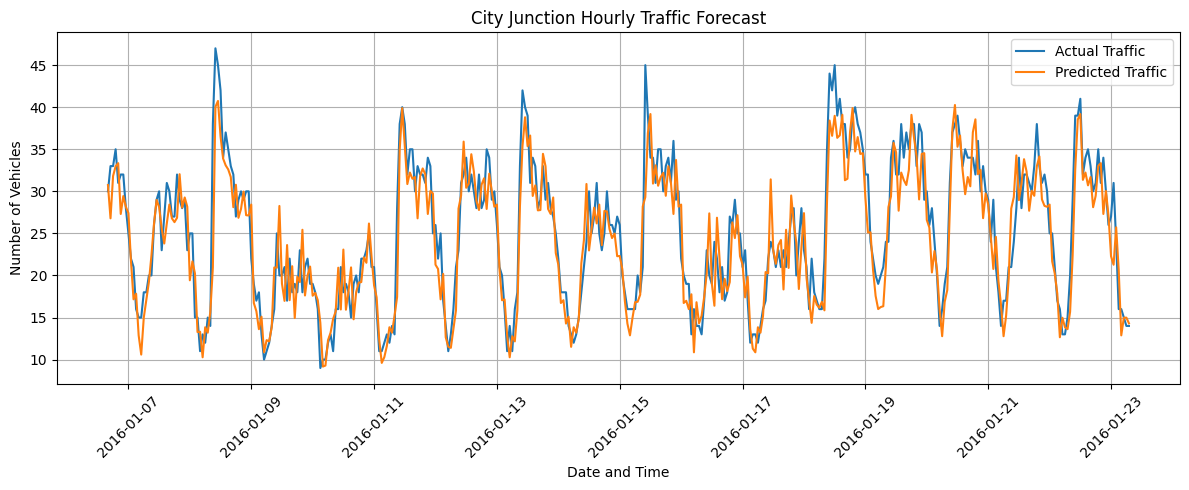

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label='Actual Traffic')
plt.plot(y_test.index, pred, label='Predicted Traffic')
plt.title('City Junction Hourly Traffic Forecast')
plt.xlabel('Date and Time')
plt.ylabel('Number of Vehicles')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()